In [1]:
import pandas as pd
import numpy as np

In [34]:
df = pd.read_csv('/content/play_tennis.csv')

In [5]:
df

,day,outlook,temp,humidity,wind,play
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes
5,D6,Rain,Cool,Normal,Strong,No
6,D7,Overcast,Cool,Normal,Strong,Yes
7,D8,Sunny,Mild,High,Weak,No
8,D9,Sunny,Cool,Normal,Weak,Yes
9,D10,Rain,Mild,Normal,Weak,Yes


In [6]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [7]:
# encode categorical --> Numeric

In [8]:
le = {}
df_enc = df.copy()
for col in df.columns:
  le[col] = LabelEncoder()
  df_enc[col] = le[col].fit_transform(df[col])

In [9]:
df_enc

,day,outlook,temp,humidity,wind,play
0,0,2,1,0,1,0
1,6,2,1,0,0,0
2,7,0,1,0,1,1
3,8,1,2,0,1,1
4,9,1,0,1,1,1
5,10,1,0,1,0,0
6,11,0,0,1,0,1
7,12,2,2,0,1,0
8,13,2,0,1,1,1
9,1,1,2,1,1,1


In [10]:
# features & Target


In [11]:
X = df_enc[['day','outlook','temp','humidity','wind']]
Y = df_enc['play']

In [12]:
X


,day,outlook,temp,humidity,wind
0,0,2,1,0,1
1,6,2,1,0,0
2,7,0,1,0,1
3,8,1,2,0,1
4,9,1,0,1,1
5,10,1,0,1,0
6,11,0,0,1,0
7,12,2,2,0,1
8,13,2,0,1,1
9,1,1,2,1,1


In [13]:
Y

,play
0,0
1,0
2,1
3,1
4,1
5,0
6,1
7,0
8,1
9,1


In [14]:
model = CategoricalNB()
model.fit(X,Y)

CategoricalNB()

In [27]:
test = [['D1', 'Sunny', 'Hot', 'High', 'Weak']]

In [24]:
test

[[0, 2, 1, 0, 1]]

In [28]:
print("-- Prediction -----------------------")
for t in test:
        row = [[
            le['day'].transform([t[0]])[0],
            le['outlook'].transform([t[1]])[0],
            le['temp'].transform([t[2]])[0],
            le['humidity'].transform([t[3]])[0],
            le['wind'].transform([t[4]])[0]
        ]]
        pred = le['play'].inverse_transform(model.predict(row))[0]
        prob = model.predict_proba(row)[0]
        print(f"Input : day={t[0]}, outlook={t[1]}, temp={t[2]}, humidity={t[3]}, wind={t[4]}")
        print(f"Result : play -> {pred}")
        print(f"P(No) = {prob[0]:.4f}")
        print(f"P(Yes) = {prob[1]:.4f}")

-- Prediction -----------------------
Input : day=D1, outlook=Sunny, temp=Hot, humidity=High, wind=Weak
Result : play -> No
P(No) = 0.8422
P(Yes) = 0.1578


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [29]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X)
print(f"\nTraining Accuracy : {accuracy_score(Y, y_pred)*100:.2f}%")


Training Accuracy : 92.86%


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


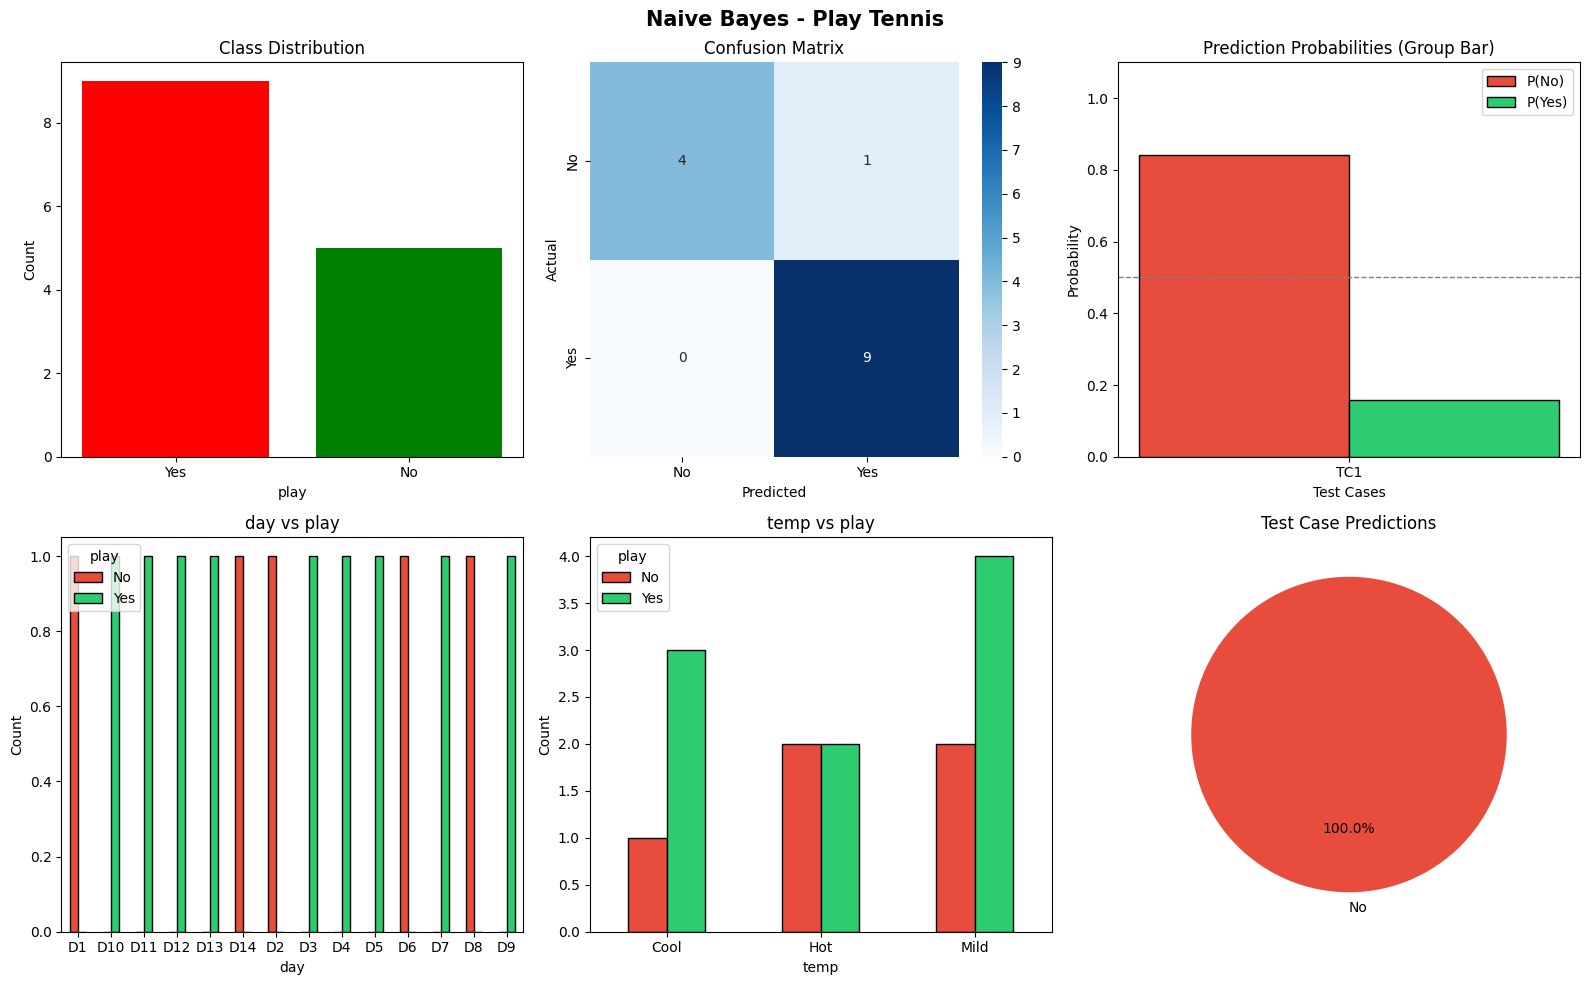

In [31]:
# Pre-calculate variables for the test predictions so the plots work
test_cases = test
probs_no = []
probs_yes = []
predictions = []

for t in test_cases:
    row_data = [[
       le['day'].transform([t[0]])[0],
       le['outlook'].transform([t[1]])[0],
       le['temp'].transform([t[2]])[0],
       le['humidity'].transform([t[3]])[0],
       le['wind'].transform([t[4]])[0]
    ]]
    prob = model.predict_proba(row_data)[0]
    pred = le['play'].inverse_transform(model.predict(row_data))[0]
    probs_no.append(prob[0])
    probs_yes.append(prob[1])
    predictions.append(pred)

# --Plots------
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle("Naive Bayes - Play Tennis", fontsize=15, fontweight='bold')

# 1. Class Distribution
counts = df['play'].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=['red', 'green'])
axes[0, 0].set_title('Class Distribution')
axes[0, 0].set_xlabel('play')
axes[0, 0].set_ylabel('Count')

# 2. Confusion Matrix
cm = confusion_matrix(Y, model.predict(X))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=axes[0, 1])
axes[0, 1].set_title('Confusion Matrix')
axes[0, 1].set_xlabel('Predicted')
axes[0, 1].set_ylabel('Actual')

# 3. Prediction Probabilities (Group Bar)
tc_lables = [f"TC{i+1}" for i in range(len(test_cases))]
x_pos = np.arange(len(tc_lables))
w = 0.3
axes[0, 2].bar(x_pos - w/2, probs_no, w, label='P(No)', color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_pos + w/2, probs_yes, w, label='P(Yes)', color='#2ecc71', edgecolor='black')
axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("Prediction Probabilities (Group Bar)")
axes[0, 2].set_xlabel('Test Cases')
axes[0, 2].set_xticks(x_pos)
axes[0, 2].set_xticklabels(tc_lables)
axes[0, 2].set_ylabel('Probability')
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

# 4. day vs play
age_counts = df.groupby(['day', 'play']).size().unstack(fill_value=0)
age_counts.plot(kind='bar', ax=axes[1, 0], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1, 0].set_title('day vs play')
axes[1, 0].set_xlabel('day')
axes[1, 0].set_ylabel('Count')
axes[1, 0].legend(title="play")

# 5. temp vs play
inc_counts = df.groupby(['temp', 'play']).size().unstack(fill_value=0)
inc_counts.plot(kind='bar', ax=axes[1, 1], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1, 1].set_title('temp vs play')
axes[1, 1].set_xlabel('temp')
axes[1, 1].set_ylabel('Count')
axes[1, 1].legend(title="play")

# 6. Pie Chart - Final Predictions
pred_counts = pd.Series(predictions).value_counts()
colors_pie = ['#2ecc71' if l == 'Yes' else '#e74c3c' for l in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, colors=colors_pie, autopct='%1.1f%%', startangle=90)
axes[1, 2].set_title('Test Case Predictions')

plt.tight_layout()
plt.show()